## Assignment  no 8

## LOGISTIC REGRESSION

1. Data Exploration

a. Load the dataset and perform exploratory data analysis (EDA).

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)

## Load the dataset

df = pd.read_csv("diabetes.csv")

print("Shape:", df.shape)
print(df.head())
print(df.tail())

Shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112 

First look at the data

In [2]:
# Quick sanity checks
print("Data types:\n", df.dtypes)
print("\nAny NaN values?\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget counts:\n", df["Outcome"].value_counts())
print("\nTarget proportions:\n", df["Outcome"].value_counts(normalize=True).round(3))

Data types:
 Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Any NaN values?
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0

Target counts:
 Outcome
0    500
1    268
Name: count, dtype: int64

Target proportions:
 Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


Detect "hidden" missing values (zeros in impossible fields)

In [3]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Zero counts in physiologically impossible columns:")
for col in zero_cols:
    n = (df[col] == 0).sum()
    print(f"  {col:<20s}: {n:>4d}  ({100*n/len(df):5.1f}%)")

Zero counts in physiologically impossible columns:
  Glucose             :    5  (  0.7%)
  BloodPressure       :   35  (  4.6%)
  SkinThickness       :  227  ( 29.6%)
  Insulin             :  374  ( 48.7%)
  BMI                 :   11  (  1.4%)


Visualizations

1. Histograms of every feature

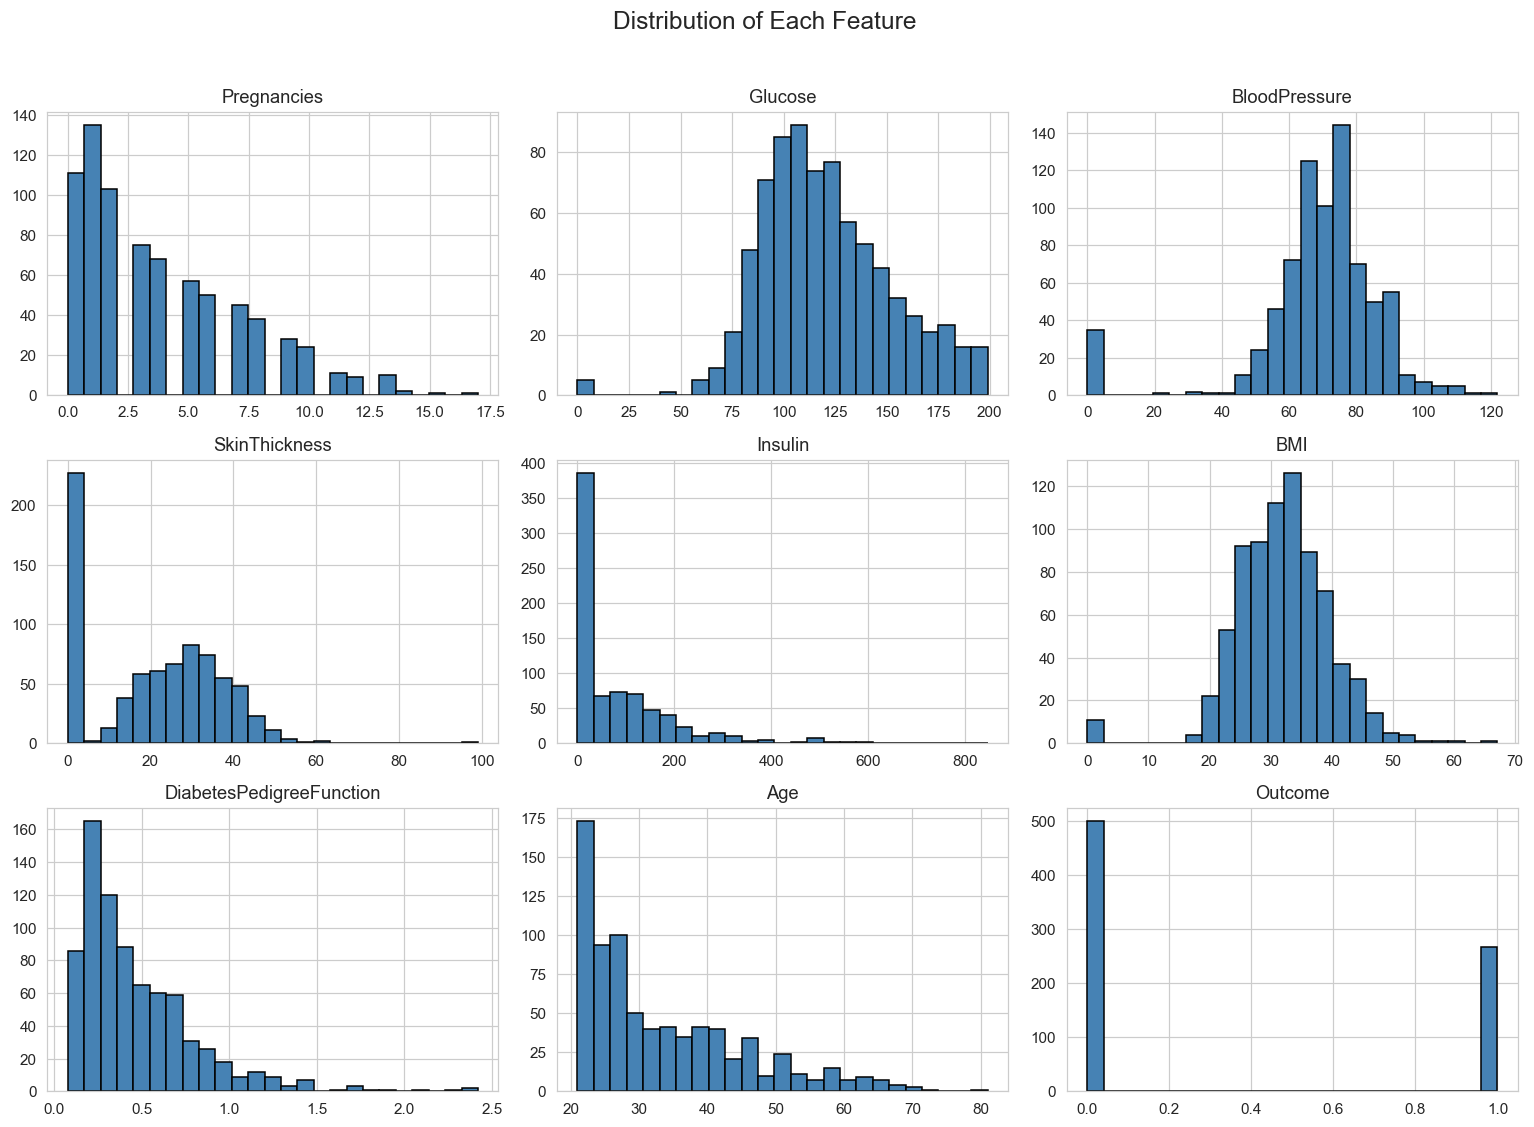

In [4]:
# Histograms
df.hist(figsize=(14, 10), bins=25, edgecolor="black", color="steelblue")
plt.suptitle("Distribution of Each Feature", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


2. Count plot of the target

C:\Users\yashr\AppData\Local\Temp\ipykernel_844\288619834.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Outcome", data=df, palette="Set2")


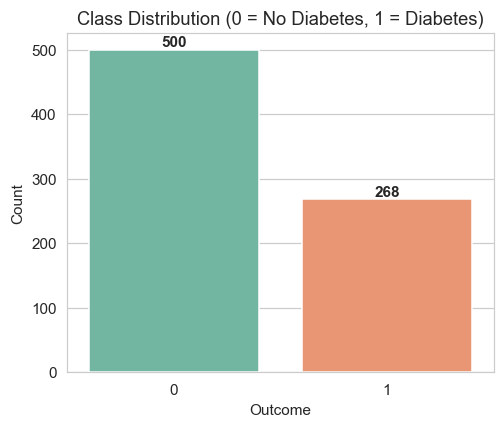

In [5]:
plt.figure(figsize=(5, 4))
sns.countplot(x="Outcome", data=df, palette="Set2")
plt.title("Class Distribution (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Count")
for i, v in enumerate(df["Outcome"].value_counts().sort_index()):
    plt.text(i, v + 5, str(v), ha="center", fontweight="bold")
plt.show()

3. Box plots — feature vs. Outcome

C:\Users\yashr\AppData\Local\Temp\ipykernel_844\3479939581.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Outcome", y=col, data=df, ax=ax, palette="Set3")
C:\Users\yashr\AppData\Local\Temp\ipykernel_844\3479939581.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Outcome", y=col, data=df, ax=ax, palette="Set3")
C:\Users\yashr\AppData\Local\Temp\ipykernel_844\3479939581.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Outcome", y=col, data=df, ax=ax, palette="Set3")
C:\Users\yashr\AppData\Local\Temp\ipykernel_844\3479939581

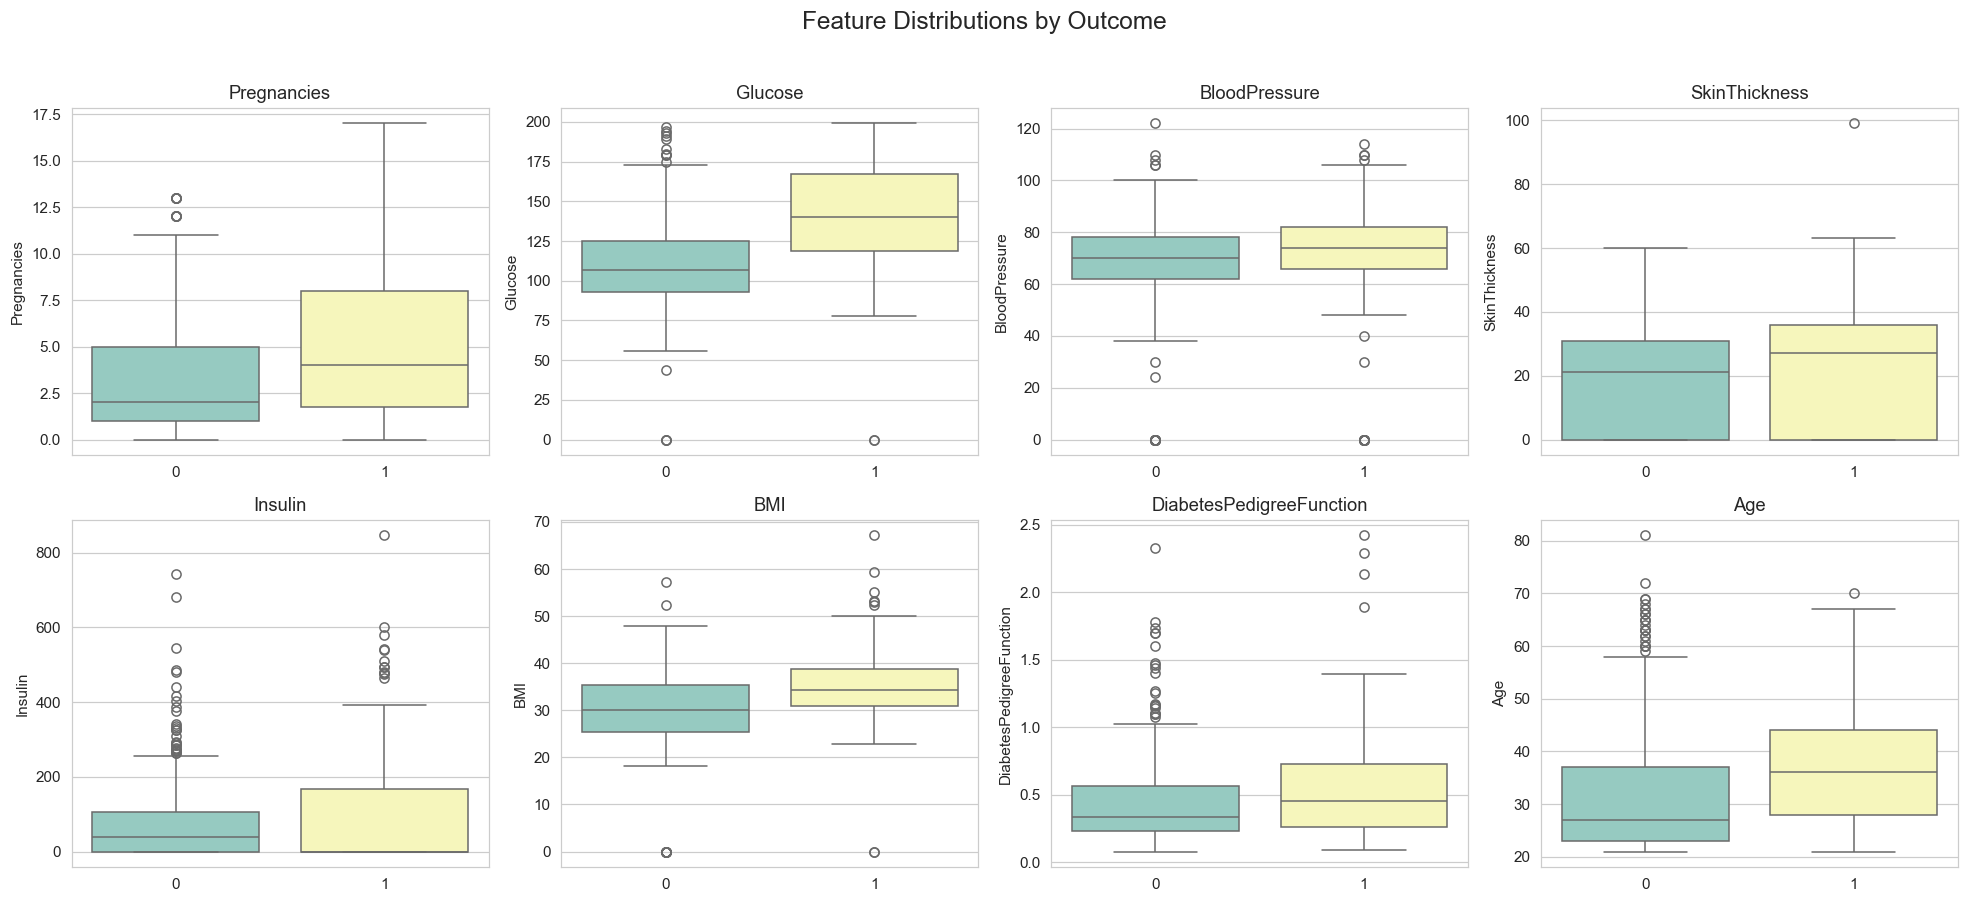

In [6]:
features = df.columns[:-1]  # all except target

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(x="Outcome", y=col, data=df, ax=ax, palette="Set3")
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Feature Distributions by Outcome", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


4. Distribution plots — key features split by outcome

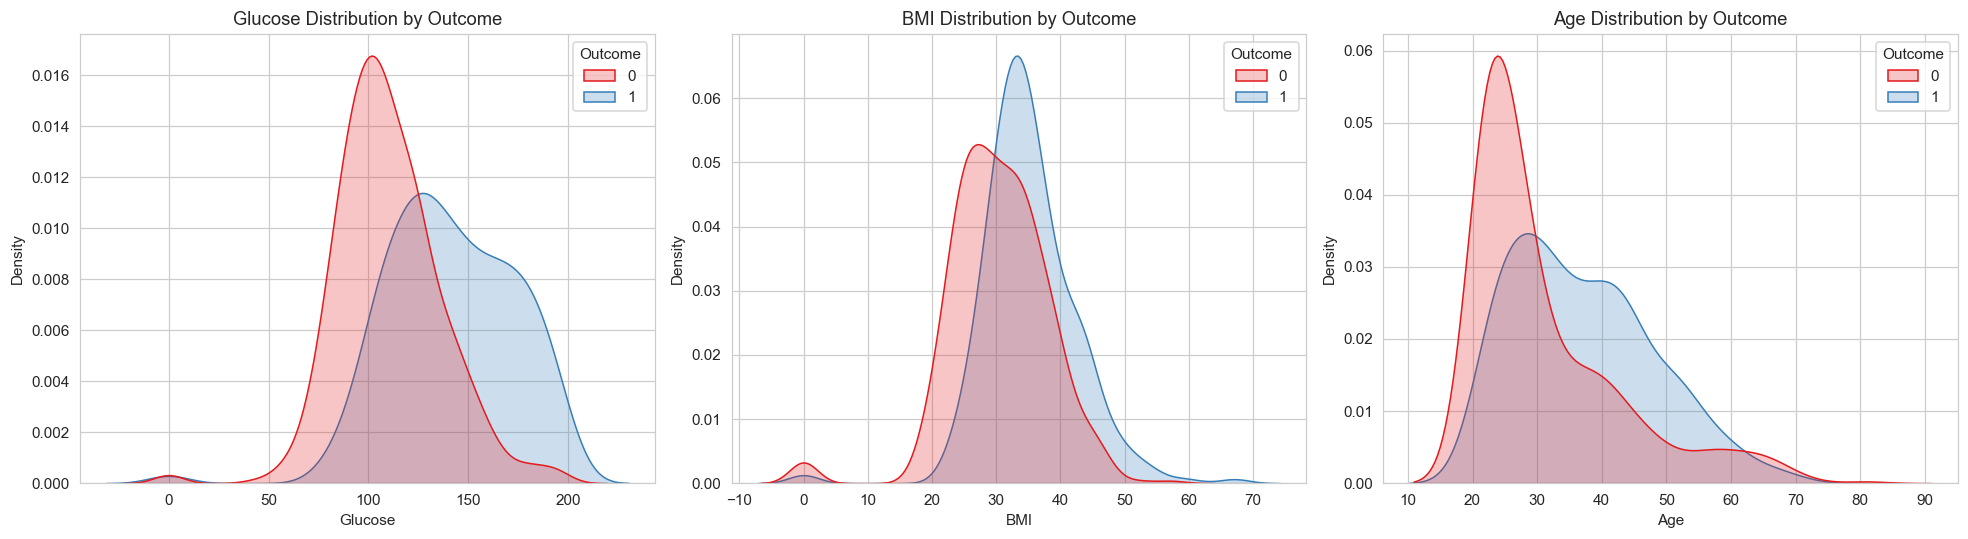

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["Glucose", "BMI", "Age"]):
    sns.kdeplot(data=df, x=col, hue="Outcome", fill=True,
                common_norm=False, palette="Set1", ax=ax)
    ax.set_title(f"{col} Distribution by Outcome")
plt.tight_layout()
plt.show()

5. Correlation heatmap

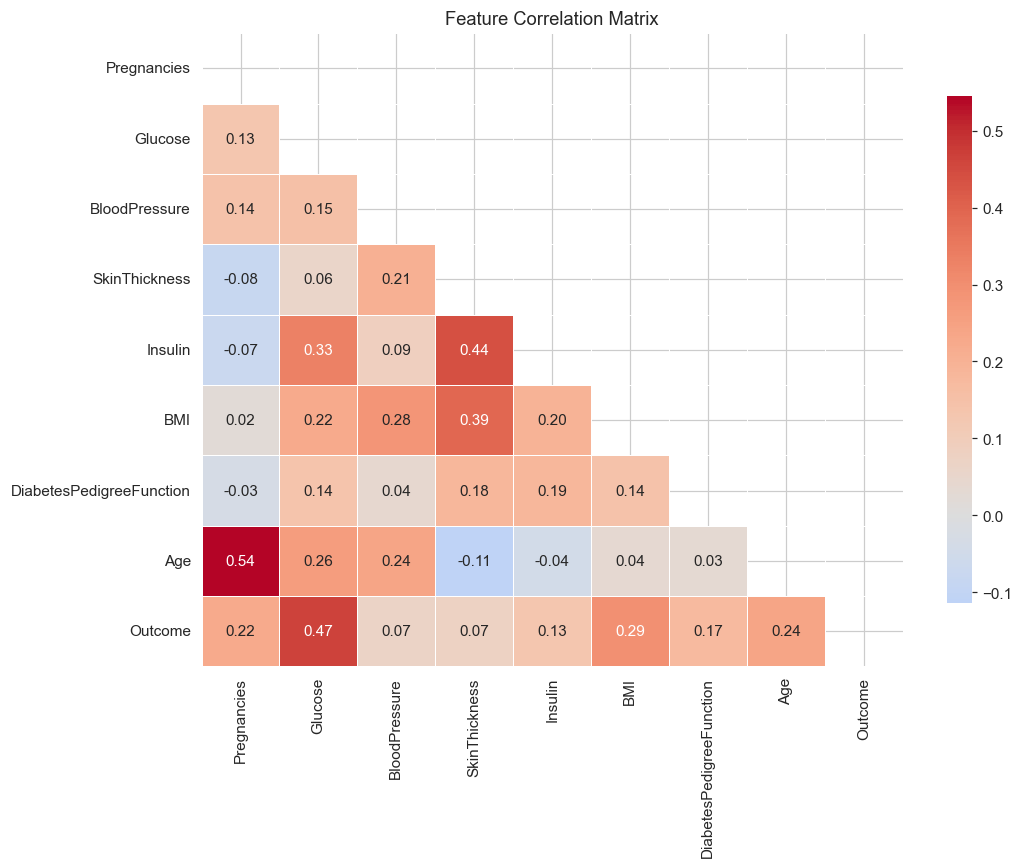


Correlation with Outcome (sorted):
Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64


In [8]:
plt.figure(figsize=(10, 8))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))          # hide upper triangle
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.5,
            cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

# Correlations with the target (ranked)
print("\nCorrelation with Outcome (sorted):")
print(df.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(3))

6. Pair plot of the strongest features

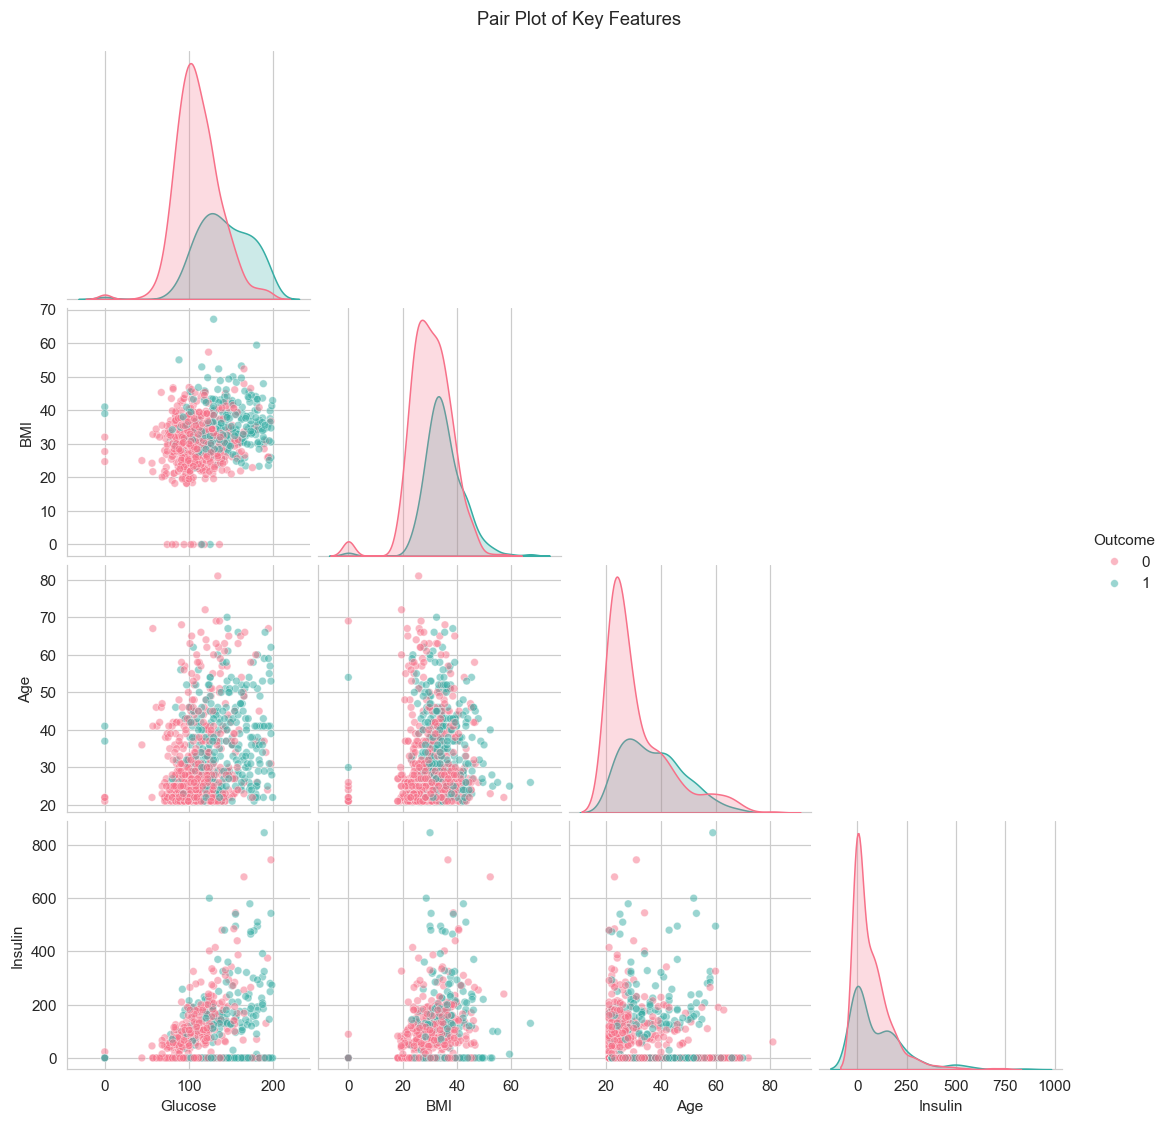

In [9]:
sns.pairplot(
    df[["Glucose", "BMI", "Age", "Insulin", "Outcome"]],
    hue="Outcome", diag_kind="kde", corner=True,
    palette="husl", plot_kws={"alpha": 0.5, "s": 25}
)
plt.suptitle("Pair Plot of Key Features", y=1.02)
plt.show()

b. Examine the features, their types, and summary statistics.

In [10]:
import pandas as pd
import numpy as np

df = pd.read_csv("diabetes.csv")


1. Feature inventory — names, types, roles

In [11]:
# Separate target from predictors
target = "Outcome"
features = [c for c in df.columns if c != target]

# Build a compact inventory table
inventory = pd.DataFrame({
    "dtype":     df.dtypes,
    "role":      ["target" if c == target else "predictor" for c in df.columns],
    "non_null":  df.notna().sum(),
    "n_unique":  df.nunique(),
    "min":       df.min(),
    "max":       df.max(),
})
print(inventory)

                            dtype       role  non_null  n_unique     min  \
Pregnancies                 int64  predictor       768        17   0.000   
Glucose                     int64  predictor       768       136   0.000   
BloodPressure               int64  predictor       768        47   0.000   
SkinThickness               int64  predictor       768        51   0.000   
Insulin                     int64  predictor       768       186   0.000   
BMI                       float64  predictor       768       248   0.000   
DiabetesPedigreeFunction  float64  predictor       768       517   0.078   
Age                         int64  predictor       768        52  21.000   
Outcome                     int64     target       768         2   0.000   

                             max  
Pregnancies                17.00  
Glucose                   199.00  
BloodPressure             122.00  
SkinThickness              99.00  
Insulin                   846.00  
BMI                        67

In [12]:
# Type grouping
print("Integer columns:", df.select_dtypes("int64").columns.tolist())
print("Float columns  :", df.select_dtypes("float64").columns.tolist())
print("Object/category:", df.select_dtypes(include=["object","category"]).columns.tolist())
print("Boolean        :", df.select_dtypes(include=["bool"]).columns.tolist())

Integer columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'Age', 'Outcome']
Float columns  : ['BMI', 'DiabetesPedigreeFunction']
Object/category: []
Boolean        : []


2. Missing values (explicit) and cardinality

In [13]:
summary_meta = pd.DataFrame({
    "non_null":   df.notna().sum(),
    "null":       df.isna().sum(),
    "null_pct":   (df.isna().mean() * 100).round(2),
    "n_unique":   df.nunique(),
    "dtype":      df.dtypes,
})
print(summary_meta)

                          non_null  null  null_pct  n_unique    dtype
Pregnancies                    768     0       0.0        17    int64
Glucose                        768     0       0.0       136    int64
BloodPressure                  768     0       0.0        47    int64
SkinThickness                  768     0       0.0        51    int64
Insulin                        768     0       0.0       186    int64
BMI                            768     0       0.0       248  float64
DiabetesPedigreeFunction       768     0       0.0       517  float64
Age                            768     0       0.0        52    int64
Outcome                        768     0       0.0         2    int64


3. Descriptive statistics (the core of 1b)

In [14]:
# Full describe table, transposed for readability
stats = df.describe().T

# Add useful derived stats
stats["range"] = stats["max"] - stats["min"]
stats["IQR"]   = stats["75%"] - stats["25%"]
stats["cv"]    = (stats["std"] / stats["mean"]).round(2)   # coefficient of variation
stats["skew"]  = df.skew().round(2)
stats["kurt"]  = df.kurtosis().round(2)

print(stats.round(2))

                          count    mean     std    min    25%     50%     75%  \
Pregnancies               768.0    3.85    3.37   0.00   1.00    3.00    6.00   
Glucose                   768.0  120.89   31.97   0.00  99.00  117.00  140.25   
BloodPressure             768.0   69.11   19.36   0.00  62.00   72.00   80.00   
SkinThickness             768.0   20.54   15.95   0.00   0.00   23.00   32.00   
Insulin                   768.0   79.80  115.24   0.00   0.00   30.50  127.25   
BMI                       768.0   31.99    7.88   0.00  27.30   32.00   36.60   
DiabetesPedigreeFunction  768.0    0.47    0.33   0.08   0.24    0.37    0.63   
Age                       768.0   33.24   11.76  21.00  24.00   29.00   41.00   
Outcome                   768.0    0.35    0.48   0.00   0.00    0.00    1.00   

                             max   range     IQR    cv  skew  kurt  
Pregnancies                17.00   17.00    5.00  0.88  0.90  0.16  
Glucose                   199.00  199.00   41.25  0

4. Distribution shape check (skewness & kurtosis, sorted)

In [15]:
sk = pd.DataFrame({
    "skewness": df.skew(),
    "kurtosis": df.kurtosis(),
}).sort_values("skewness", ascending=False).round(2)
print(sk)

                          skewness  kurtosis
Insulin                       2.27      7.21
DiabetesPedigreeFunction      1.92      5.59
Age                           1.13      0.64
Pregnancies                   0.90      0.16
Outcome                       0.64     -1.60
Glucose                       0.17      0.64
SkinThickness                 0.11     -0.52
BMI                          -0.43      3.29
BloodPressure                -1.84      5.18


5. Quantile inspection (outlier awareness)

In [16]:
quant = df.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T.round(2)
print(quant)

                           0.01   0.05   0.25    0.50    0.75    0.95    0.99
Pregnancies                0.00   0.00   1.00    3.00    6.00   10.00   13.00
Glucose                   57.00  79.00  99.00  117.00  140.25  181.00  196.00
BloodPressure              0.00  38.70  62.00   72.00   80.00   90.00  106.00
SkinThickness              0.00   0.00   0.00   23.00   32.00   44.00   51.33
Insulin                    0.00   0.00   0.00   30.50  127.25  293.00  519.90
BMI                        0.00  21.80  27.30   32.00   36.60   44.40   50.76
DiabetesPedigreeFunction   0.09   0.14   0.24    0.37    0.63    1.13    1.70
Age                       21.00  21.00  24.00   29.00   41.00   58.00   67.00
Outcome                    0.00   0.00   0.00    0.00    1.00    1.00    1.00


6. Target summary statistics (per class)

In [17]:
target_stats = df.groupby("Outcome").mean().T.round(2)
target_stats["diff_(1-0)"] = (target_stats[1] - target_stats[0]).round(2)
print(target_stats)

Outcome                        0       1  diff_(1-0)
Pregnancies                 3.30    4.87        1.57
Glucose                   109.98  141.26       31.28
BloodPressure              68.18   70.82        2.64
SkinThickness              19.66   22.16        2.50
Insulin                    68.79  100.34       31.55
BMI                        30.30   35.14        4.84
DiabetesPedigreeFunction    0.43    0.55        0.12
Age                        31.19   37.07        5.88


2. Data Preprocessing:

2a. Handle Missing Values


Step 1 — Diagnose: what's actually missing?

In [18]:
import pandas as pd
import numpy as np

df = pd.read_csv("diabetes.csv")

# 1) Explicit NaNs
print("Explicit NaN counts:")
print(df.isna().sum())
print()

# 2) Hidden NaNs encoded as 0 in physically impossible columns
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zeros in clinically impossible columns (hidden missing):")
for col in zero_as_missing:
    n = (df[col] == 0).sum()
    print(f"  {col:<16s}: {n:>4d}  ({100*n/len(df):5.1f}%)")

Explicit NaN counts:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zeros in clinically impossible columns (hidden missing):
  Glucose         :    5  (  0.7%)
  BloodPressure   :   35  (  4.6%)
  SkinThickness   :  227  ( 29.6%)
  Insulin         :  374  ( 48.7%)
  BMI             :   11  (  1.4%)


Step 2 — Convert impossible zeros to NaN

In [19]:
df_clean = df.copy()
df_clean[zero_as_missing] = df_clean[zero_as_missing].replace(0, np.nan)

print(df_clean.isna().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


Step 4 — Split FIRST, then fit imputer on train only (no leakage)

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y           # preserve ~65/35 class ratio in both splits
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train class ratio:", y_train.mean().round(3),
      "| Test class ratio:", y_test.mean().round(3))

imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)     # fit on TRAIN only
X_test_imp  = imputer.transform(X_test)          # apply the same medians

print("\nImputed medians learned on training set:")
print(dict(zip(X.columns, imputer.statistics_.round(2))))

Train: (614, 8) Test: (154, 8)
Train class ratio: 0.349 | Test class ratio: 0.351

Imputed medians learned on training set:
{'Pregnancies': 3.0, 'Glucose': 117.0, 'BloodPressure': 72.0, 'SkinThickness': 29.0, 'Insulin': 125.0, 'BMI': 32.4, 'DiabetesPedigreeFunction': 0.38, 'Age': 29.0}


Step 5 — Verify: no NaN left, distributions preserved

NaN after imputation: 0
NaN in test       : 0


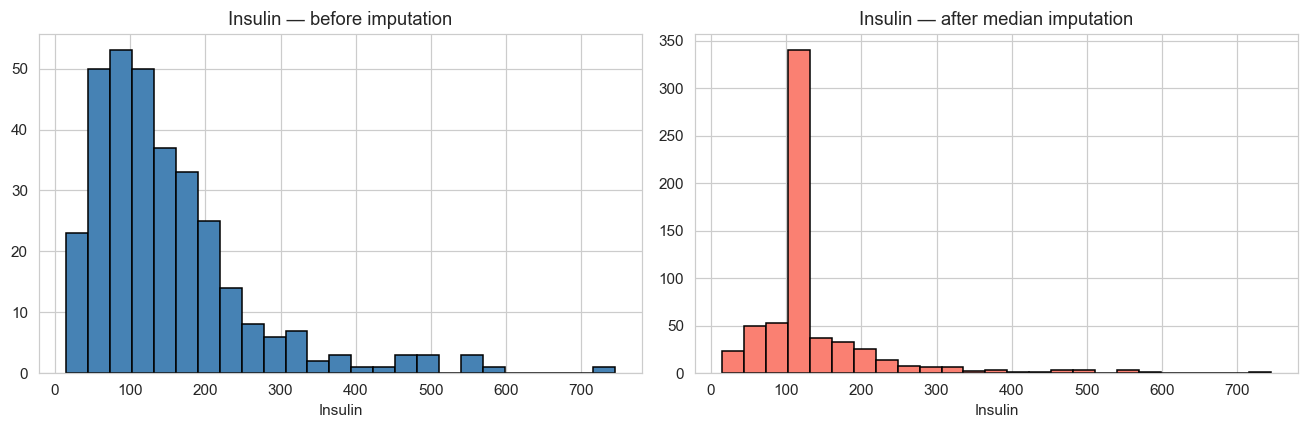

In [21]:
print("NaN after imputation:", np.isnan(X_train_imp).sum())
print("NaN in test       :", np.isnan(X_test_imp).sum())

# Compare before vs after for a heavily-missing column
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_train["Insulin"].dropna(), bins=25, color="steelblue", edgecolor="k")
axes[0].set_title("Insulin — before imputation")
axes[1].hist(X_train_imp[:, list(X.columns).index("Insulin")],
             bins=25, color="salmon", edgecolor="k")
axes[1].set_title("Insulin — after median imputation")
for ax in axes: ax.set_xlabel("Insulin")
plt.tight_layout(); plt.show()

Step 6 — Alternative strategies (for completeness)

In [22]:
# 1) Group-wise median (sometimes better: median per Outcome class)
#    — but this leaks the target if used naively; do inside CV if you try it.

# 2) KNN imputation — better when features are correlated
from sklearn.impute import KNNImputer
knn_imp = KNNImputer(n_neighbors=5)
X_knn = knn_imp.fit_transform(X_train)

# 3) Iterative imputer (MICE-style)
from sklearn.experimental import enable_iterative_imputer   # noqa
from sklearn.impute import IterativeImputer
iter_imp = IterativeImputer(random_state=42, max_iter=10)
X_iter = iter_imp.fit_transform(X_train)

2b. Encode Categorical Variables

In [23]:
cat_cols = df_clean.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print("Categorical columns:", cat_cols)   # → []

from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

# --- Example: assume df has a new column 'BloodType' with 4 categories
df_example = df_clean.copy()
np.random.seed(0)
df_example["BloodType"] = np.random.choice(["A", "B", "AB", "O"], size=len(df_example))

cat_cols = ["BloodType"]
num_cols = [c for c in df_example.columns if c not in cat_cols + ["Outcome"]]

# ---- OPTION 1: One-Hot (nominal — no order)
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
# drop='first' avoids the dummy-variable trap (perfect collinearity)

# ---- OPTION 2: Ordinal (only when categories have a natural order)
# Example: if BMI were binned into Under<Normal<Over<Obese
# ordinal = OrdinalEncoder(categories=[["Under","Normal","Over","Obese"]])

# Apply both to the right columns via ColumnTransformer
preprocess_ct = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),          # numeric → untouched here
        ("cat", ohe,             cat_cols),        # categorical → one-hot
    ],
    remainder="drop",
)

X_enc = preprocess_ct.fit_transform(df_example.drop("Outcome", axis=1))
print("Encoded shape:", X_enc.shape)
print("New feature names:", preprocess_ct.get_feature_names_out())

Categorical columns: []
Encoded shape: (768, 11)
New feature names: ['num__Pregnancies' 'num__Glucose' 'num__BloodPressure'
 'num__SkinThickness' 'num__Insulin' 'num__BMI'
 'num__DiabetesPedigreeFunction' 'num__Age' 'cat__BloodType_AB'
 'cat__BloodType_B' 'cat__BloodType_O']


Putting it all together — the production-ready pipeline

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Note: the 0→NaN replacement happens BEFORE the pipeline
#       (on X_train / X_test separately, using the same logic)
X_train_nan = X_train.replace(0, np.nan) if False else X_train  # already NaN from df_clean

pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # 2a: handle missing
    ("scaler",  StandardScaler()),                   # scale (needed for logit coefficients)
    # ("encoder", ColumnTransformer(...))            # 2b: add only if categoricals exist
    ("clf",     LogisticRegression(max_iter=1000, random_state=42)),
])

pipe.fit(X_train, y_train)
print("Pipeline trained on", X_train.shape[0], "samples")

Pipeline trained on 614 samples


3. Model Building:

3a. Build the Logistic Regression Model

Step 1 — Recreate the clean data and split (from step 2)

In [25]:
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# ---------- Load + clean ----------
df = pd.read_csv("diabetes.csv")

zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# ---------- Stratified train/test split ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train positive rate:", y_train.mean().round(3))
print("Test  positive rate:", y_test.mean().round(3))

Train: (614, 8)  Test: (154, 8)
Train positive rate: 0.349
Test  positive rate: 0.351


Step 2 — Build the Pipeline

In [26]:
pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),   # 2a
    ("scaler",  StandardScaler()),                   # scale for comparability
    ("clf",     LogisticRegression(
        penalty="l2",
        C=1.0,                 # inverse regularization strength
        solver="lbfgs",
        max_iter=1000,
        random_state=42,
        class_weight=None,     # we'll try 'balanced' below as a variant
    )),
])
pipe

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

Step 3 — Sanity check before fitting

In [27]:
# Confirm the pipeline is well-formed and produces the expected stages
print(pipe.get_params()["clf"])     # LogisticRegression default params
print("\nNumber of stages:", len(pipe.steps))

LogisticRegression(max_iter=1000, random_state=42)

Number of stages: 3


3b. Train the Model on the Training Data

In [28]:
# ---------- Train ----------
pipe.fit(X_train, y_train)
print("Model trained on", X_train.shape[0], "samples with", X_train.shape[1], "features.")

Model trained on 614 samples with 8 features.


Step 1 — Confirm the fit is healthy (no convergence issues)

In [29]:
clf = pipe.named_steps["clf"]

# Convergence diagnostics
print("n_iter_ (iterations used):", clf.n_iter_)          # << max_iter → converged
print("Classes:", clf.classes_)                            # [0 1]
print("Intercept (β0):", clf.intercept_.round(3))

# Learned coefficients (standardized scale)
coefs = pd.Series(clf.coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
print("\nCoefficients (standardized):\n", coefs.round(3))

n_iter_ (iterations used): [8]
Classes: [0 1]
Intercept (β0): [-0.872]

Coefficients (standardized):
 Glucose                     1.183
BMI                         0.689
Pregnancies                 0.377
DiabetesPedigreeFunction    0.233
Age                         0.148
Insulin                    -0.066
BloodPressure              -0.044
SkinThickness               0.028
dtype: float64


Step 2 — Sanity check on probabilities

In [30]:
# Predict probabilities and check they're in [0, 1]
proba_train = pipe.predict_proba(X_train)[:, 1]
print("Train probs  -> min:", proba_train.min().round(3),
      "max:", proba_train.max().round(3),
      "mean:", proba_train.mean().round(3))
print("Actual positive rate:", y_train.mean().round(3))

# Predictions (default 0.5 threshold)
pred_train = pipe.predict(X_train)
print("Predicted positive rate:", pred_train.mean().round(3))

Train probs  -> min: 0.01 max: 0.975 mean: 0.349
Actual positive rate: 0.349
Predicted positive rate: 0.269


Step 5 — Save the trained model

In [31]:
import joblib

# `pipe` was fitted in §3b: pipe.fit(X_train, y_train)
joblib.dump(pipe, "diabetes_model.pkl")
print("Saved diabetes_model.pkl")

# Round-trip check
loaded = joblib.load("diabetes_model.pkl")
print("Load OK — predict_proba sample:",
      loaded.predict_proba(X_test.iloc[:3]).round(3))

Saved diabetes_model.pkl
Load OK — predict_proba sample: [[0.39  0.61 ]
 [0.882 0.118]
 [0.707 0.293]]


4. Model Evaluation:

4a. Evaluate the Model on the Test Set

Step 1 — Select the fitted model and generate predictions

In [32]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    classification_report, confusion_matrix,
)

# Use `best_pipe` if it exists (tuned), otherwise fall back to `pipe` (default)
model = globals().get("best_pipe") or globals().get("pipe")
if model is None or not hasattr(model, "feature_names_in_"):
    raise RuntimeError("No fitted pipeline found — run §3b fitting first.")

# Hard labels at the default 0.5 threshold, and P(class=1) for AUC/ROC
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

Step 2 — Compute the five headline metrics

In [33]:
metrics = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1-score":  f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_prob),
}

print("=" * 42)
print(f"{'Metric':<12s}{'Score':>10s}")
print("=" * 42)
for name, value in metrics.items():
    print(f"{name:<12s}{value:>10.4f}")
print("=" * 42)

Metric           Score
Accuracy        0.7078
Precision       0.6000
Recall          0.5000
F1-score        0.5455
ROC-AUC         0.8130


Step 3 — Confusion matrix + classification report (context for the numbers)

In [34]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Confusion matrix:  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Specificity (TNR): {tn/(tn+fp):.3f}")
print(f"Sensitivity (TPR): {tp/(tp+fn):.3f}\n")

print(classification_report(
    y_test, y_pred,
    target_names=["No diabetes (0)", "Diabetes (1)"],
    digits=3,
))

Confusion matrix:  TN=82  FP=18  FN=27  TP=27
Specificity (TNR): 0.820
Sensitivity (TPR): 0.500

                 precision    recall  f1-score   support

No diabetes (0)      0.752     0.820     0.785       100
   Diabetes (1)      0.600     0.500     0.545        54

       accuracy                          0.708       154
      macro avg      0.676     0.660     0.665       154
   weighted avg      0.699     0.708     0.701       154



Step 4 — Visualize the ROC curve

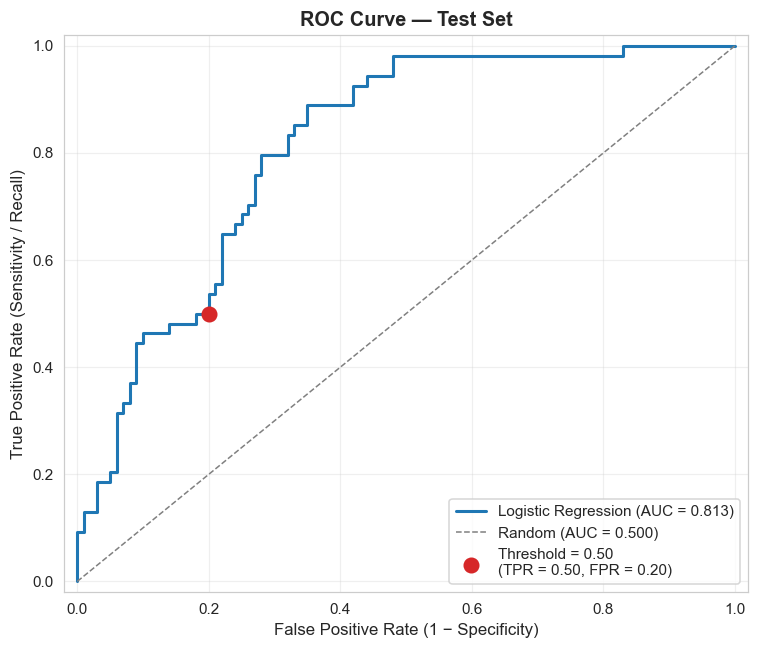

In [35]:
# Compute ROC coordinates and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_value = roc_auc_score(y_test, y_prob)

# Operating point at the default 0.5 threshold (for reference on the curve)
j = np.argmin(np.abs(thresholds - 0.5))

fig, ax = plt.subplots(figsize=(7, 6))

# The ROC curve itself
ax.plot(fpr, tpr, color="tab:blue", lw=2,
        label=f"Logistic Regression (AUC = {auc_value:.3f})")

# Diagonal = random classifier
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1,
        label="Random (AUC = 0.500)")

# Highlight the 0.5-threshold operating point
ax.scatter(fpr[j], tpr[j], s=90, color="tab:red", zorder=5,
           label=f"Threshold = 0.50\n(TPR = {tpr[j]:.2f}, FPR = {fpr[j]:.2f})")

ax.set_xlabel("False Positive Rate (1 − Specificity)", fontsize=11)
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
ax.set_title("ROC Curve — Test Set", fontsize=13, fontweight="bold")
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])
ax.grid(alpha=0.3)
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

5. Interpretation:

a. Interpreting the Coefficients


Step 1 — Extract coefficients and convert to odds ratios

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

clf = model.named_steps["clf"]
feature_names = model.named_steps["scaler"].get_feature_names_out()  # same order as X

coef_df = pd.DataFrame({
    "coef_logodds": clf.coef_[0],
    "odds_ratio":   np.exp(clf.coef_[0]),
    "%_change_odds": (np.exp(clf.coef_[0]) - 1) * 100,
}, index=feature_names)

# Sort by absolute standardized coefficient
coef_df = coef_df.reindex(coef_df["coef_logodds"].abs().sort_values(ascending=False).index)

print(f"Intercept (log-odds): {clf.intercept_[0]:.4f}")
print(f"Intercept (odds)    : {np.exp(clf.intercept_[0]):.4f}\n")
print(coef_df.round(3))

Intercept (log-odds): -0.8722
Intercept (odds)    : 0.4180

    coef_logodds  odds_ratio  %_change_odds
x1         1.183       3.263        226.274
x5         0.689       1.991         99.103
x0         0.377       1.459         45.855
x6         0.233       1.263         26.281
x7         0.148       1.159         15.927
x4        -0.066       0.936         -6.398
x2        -0.044       0.957         -4.315
x3         0.028       1.029          2.873


Coefficient plot (forest-style)

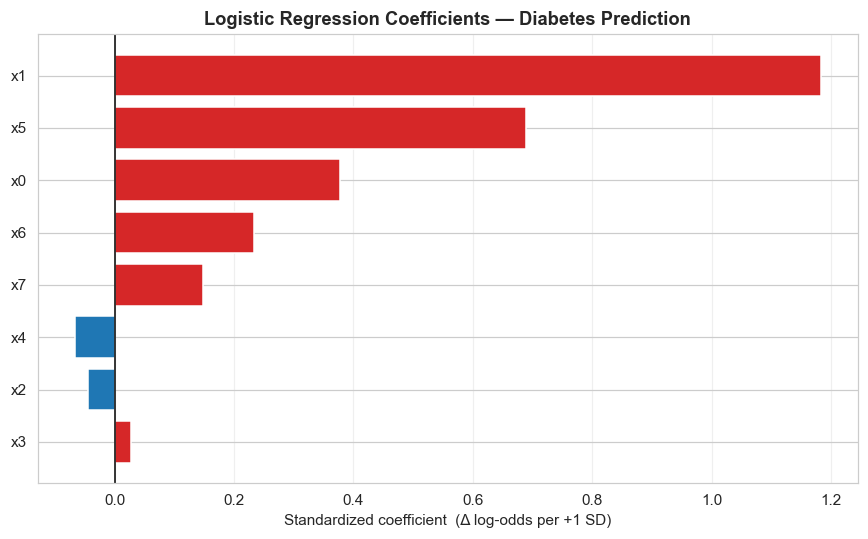

In [37]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["tab:red" if c > 0 else "tab:blue" for c in coef_df["coef_logodds"]]
ax.barh(coef_df.index, coef_df["coef_logodds"], color=colors)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Standardized coefficient  (Δ log-odds per +1 SD)")
ax.set_title("Logistic Regression Coefficients — Diabetes Prediction",
             fontweight="bold")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

Convert coefficients back to the raw feature scale (for intuition)

In [38]:
scaler = model.named_steps["scaler"]

raw_coef = clf.coef_[0] / scaler.scale_           # per 1 raw unit
raw_or   = np.exp(raw_coef)

raw_df = pd.DataFrame({
    "std_coef":  clf.coef_[0],
    "raw_coef":  raw_coef,
    "raw_OR":    raw_or,
}, index=feature_names).reindex(coef_df.index)

print(raw_df.round(4))

    std_coef  raw_coef  raw_OR
x1    1.1826    0.0394  1.0402
x5    0.6887    0.1010  1.1063
x0    0.3774    0.1140  1.1207
x6    0.2333    0.7070  2.0279
x7    0.1478    0.0125  1.0126
x4   -0.0661   -0.0008  0.9992
x2   -0.0441   -0.0036  0.9964
x3    0.0283    0.0032  1.0032


5b. Discussing Feature Significance

Step 1 — Statistical significance via statsmodels

In [39]:
import statsmodels.api as sm

# Use the imputed + scaled training matrix from the pipeline
X_train_scaled = model.named_steps["scaler"].transform(
    model.named_steps["imputer"].transform(X_train)
)
X_train_sm = pd.DataFrame(X_train_scaled, columns=feature_names)
X_train_sm = sm.add_constant(X_train_sm)

logit_sm = sm.Logit(y_train.values, X_train_sm).fit(disp=0)
print(logit_sm.summary2().tables[1].round(4))

        Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
const -0.8772    0.1104 -7.9442  0.0000 -1.0936 -0.6608
x0     0.3857    0.1238  3.1152  0.0018  0.1430  0.6284
x1     1.2070    0.1369  8.8189  0.0000  0.9387  1.4752
x2    -0.0507    0.1180 -0.4302  0.6671 -0.2820  0.1805
x3     0.0214    0.1322  0.1621  0.8712 -0.2377  0.2806
x4    -0.0761    0.1174 -0.6486  0.5166 -0.3062  0.1539
x5     0.7060    0.1405  5.0254  0.0000  0.4306  0.9813
x6     0.2366    0.1111  2.1296  0.0332  0.0188  0.4543
x7     0.1466    0.1236  1.1856  0.2358 -0.0957  0.3889


Step 2 — A caveat worth stating out loud: multicollinearity inflates p-values

In [40]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame({
    "feature": feature_names,
    "VIF": [variance_inflation_factor(X_train_scaled, i)
            for i in range(X_train_scaled.shape[1])],
}).sort_values("VIF", ascending=False).round(2)
print(vif)

  feature   VIF
7      x7  1.60
5      x5  1.55
3      x3  1.46
0      x0  1.42
1      x1  1.40
4      x4  1.31
2      x2  1.22
6      x6  1.07


Step 4 — Bootstrap confidence intervals (sanity check that isn't dependent on asymptotic normality)

In [41]:
from sklearn.utils import resample

B = 500
boot_coefs = np.zeros((B, len(feature_names)))
rng = np.random.RandomState(42)

for b in range(B):
    Xb, yb = resample(X_train_scaled, y_train.values, random_state=rng)
    m = sm.Logit(yb, sm.add_constant(Xb)).fit(disp=0, method="lbfgs")
    boot_coefs[b] = m.params[1:]                # drop intercept

boot_ci = pd.DataFrame({
    "coef":     clf.coef_[0],
    "CI_lower": np.percentile(boot_coefs, 2.5,  axis=0),
    "CI_upper": np.percentile(boot_coefs, 97.5, axis=0),
}, index=feature_names).round(3).reindex(coef_df.index)

print(boot_ci)
print("\nFeatures whose 95% bootstrap CI excludes 0:",
      boot_ci.index[(boot_ci["CI_lower"] > 0) | (boot_ci["CI_upper"] < 0)].tolist())

     coef  CI_lower  CI_upper
x1  1.183     0.976     1.503
x5  0.689     0.486     0.990
x0  0.377     0.135     0.667
x6  0.233    -0.003     0.522
x7  0.148    -0.101     0.423
x4 -0.066    -0.345     0.209
x2 -0.044    -0.293     0.167
x3  0.028    -0.230     0.291

Features whose 95% bootstrap CI excludes 0: ['x1', 'x5', 'x0']


6. Deployment with Streamlit:

6a. The app.py — production-ready version